### Logarithmic Transformation of Pixel Values

The logarithmic transformation is a common image processing technique used to expand the range of dark pixels while compressing the range of bright pixels. It is particularly useful when an image has a very wide dynamic range or when details in the darker areas need to be enhanced. The formula for this transformation is $s = c \cdot \log(1 + r)$, where $r$ is the input pixel value, $s$ is the output pixel value, and $c$ is a scaling constant.

Here, we will implement the simplified version $p_{out} = \log(1 + p_{in})$, which is often sufficient for demonstration purposes. Python's `numpy.log1p` function efficiently computes $\log(1+x)$.

Original Grayscale Image shape: (3888, 5184)
Original Grayscale Image (first 5x5 pixels):
[[84 84 84 84 84]
 [84 84 84 84 84]
 [84 84 84 84 84]
 [84 84 84 84 84]
 [84 84 84 84 84]]

Log-Transformed Grayscale Image shape: (3888, 5184)
Log-Transformed Grayscale Image (scaled to 0-255 for display, first 5x5 pixels):
[[208 208 208 208 208]
 [208 208 208 208 208]
 [208 208 208 208 208]
 [208 208 208 208 208]
 [208 208 208 208 208]]


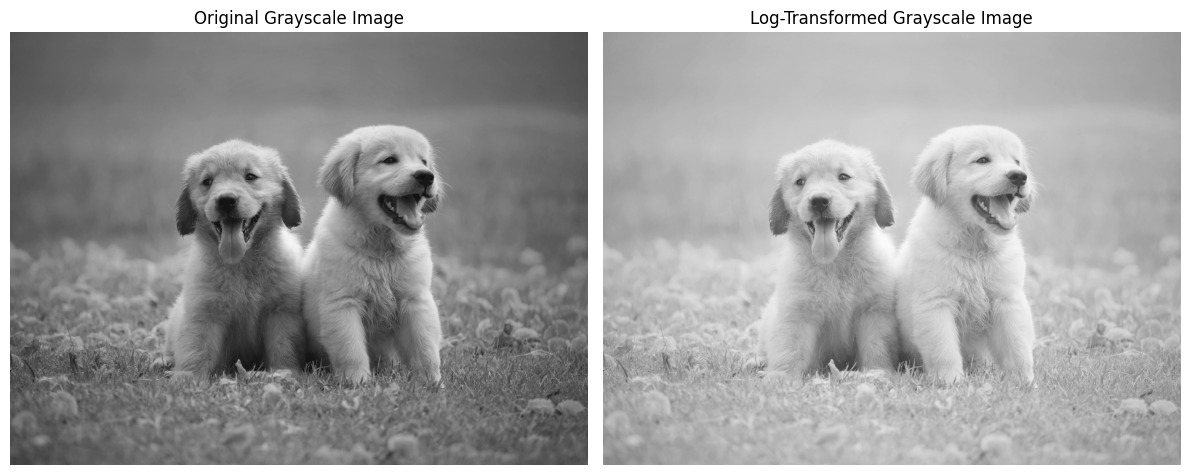

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 # Import OpenCV library

# 1. Read the image using OpenCV
original_image = cv2.imread('/content/pexels-chevanon-1108099.jpg')

# Check if image was loaded successfully
if original_image is None:
    print("Error: Image not found or could not be loaded.")
else:
    # Convert BGR to Grayscale
    original_image_gray = cv2.cvtColor(original_image, cv2.COLOR_BGR2GRAY)

    print("Original Grayscale Image shape:", original_image_gray.shape)
    print("Original Grayscale Image (first 5x5 pixels):")
    print(original_image_gray[:5, :5])

    # Apply log1p directly. np.log1p(x) computes log(1+x)
    log_transformed_image_gray = np.log1p(original_image_gray.astype(np.float32))

    # Normalize the transformed image to 0-255 for better visualization
    max_log_value = np.max(log_transformed_image_gray)
    scaled_log_image_gray = (log_transformed_image_gray / max_log_value) * 255
    scaled_log_image_gray = scaled_log_image_gray.astype(np.uint8)

    print("\nLog-Transformed Grayscale Image shape:", scaled_log_image_gray.shape)
    print("Log-Transformed Grayscale Image (scaled to 0-255 for display, first 5x5 pixels):")
    print(scaled_log_image_gray[:5, :5])

    # 3. Display the original and transformed grayscale images
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(original_image_gray, cmap='gray')
    plt.title('Original Grayscale Image')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(scaled_log_image_gray, cmap='gray')
    plt.title('Log-Transformed Grayscale Image')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

### Logarithmic Transformation using Nested Loops

While the previous method leveraged NumPy's efficient vectorized operations, it's also possible to perform this transformation by iterating through each pixel using nested loops. This can be useful for understanding the process at a fundamental level, though it's generally much slower for large images due to Python's loop overhead.


Log-Transformed Image (scaled to 0-255 for display, first 5x5 pixels of first channel) using loops:
[[200 200 200 200 200]
 [200 200 200 200 200]
 [200 200 200 200 200]
 [200 200 200 200 200]
 [200 200 200 200 200]]


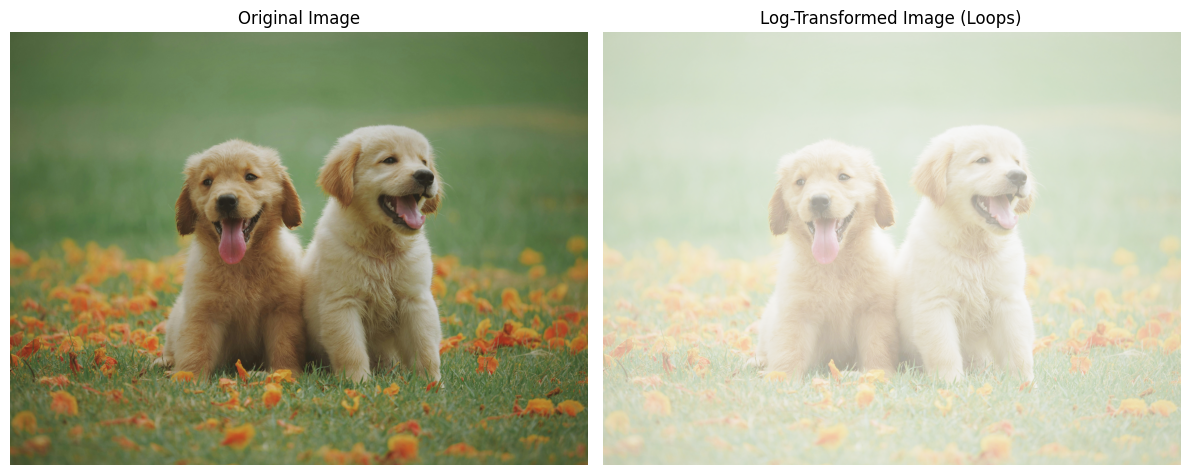

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Ensure the image is loaded and converted to RGB as before
original_image = cv2.imread('/content/pexels-chevanon-1108099.jpg')

if original_image is None:
    print("Error: Image not found or could not be loaded.")
else:
    original_image_rgb = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)

    # Create an empty array to store the transformed image
    # It's important to use float type for intermediate calculations with log
    log_transformed_image_loops = np.zeros_like(original_image_rgb, dtype=np.float32)

    # Iterate through each pixel using nested loops
    # p[i,j] = log(1 + p[i,j])
    rows, cols, channels = original_image_rgb.shape
    for i in range(rows):
        for j in range(cols):
            for c in range(channels):
                pixel_value = original_image_rgb[i, j, c]
                log_transformed_image_loops[i, j, c] = np.log1p(pixel_value)

    # Normalize the transformed image to 0-255 for better visualization
    # (Similar to the vectorized approach)
    max_log_value_loops = np.max(log_transformed_image_loops)
    scaled_log_image_loops = (log_transformed_image_loops / max_log_value_loops) * 255
    scaled_log_image_loops = scaled_log_image_loops.astype(np.uint8)

    print("\nLog-Transformed Image (scaled to 0-255 for display, first 5x5 pixels of first channel) using loops:")
    print(scaled_log_image_loops[:, :, 0][:5, :5])

    # Display the original and loop-transformed images
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(original_image_rgb)
    plt.title('Original Image')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(scaled_log_image_loops)
    plt.title('Log-Transformed Image (Loops)')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
original_image = cv2.imread('/content/pexels-chevanon-1108099.jpg')

if original_image is None:
    print("Error: Image not found or could not be loaded.")
else:
    original_image_rgb = cv2.cvtColor(original_image, cv2.COLOR_RGB2GRAY)

    # Create an empty array to store the transformed image
    # It's important to use float type for intermediate calculations with log
    log_transformed_image_loops = np.zeros_like(original_image_rgb, dtype=np.float32)

    # Iterate through each pixel using nested loops
    # p[i,j] = log(1 + p[i,j])
    rows, cols = original_image_rgb.shape
    for i in range(rows):
        for j in range(cols):
                pixel_value = original_image_rgb[i, j]
                log_transformed_image_loops[i, j] = np.log1p(pixel_value)

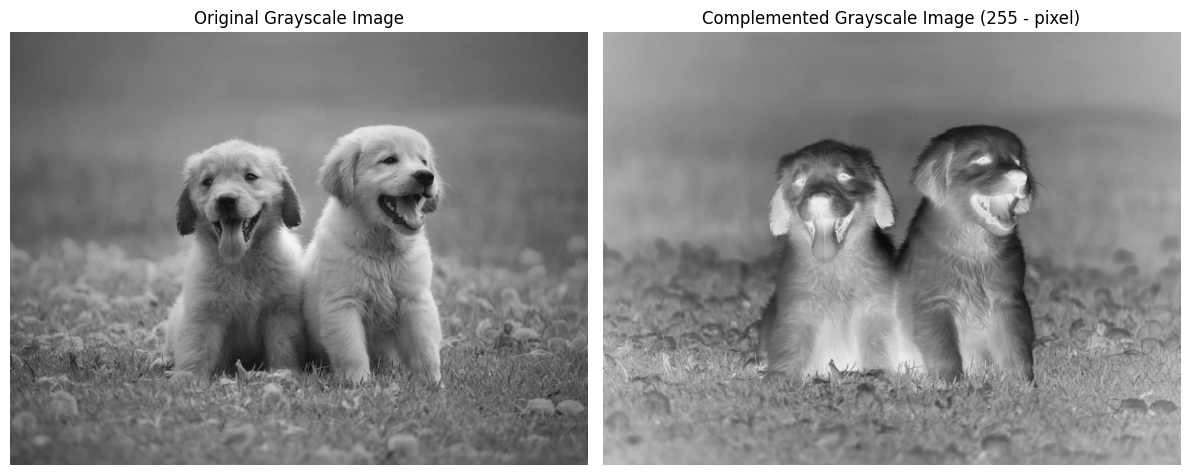

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

original_image = cv2.imread('/content/pexels-chevanon-1108099.jpg')

if original_image is None:
    print("Error: Image not found or could not be loaded for complement transformation.")
else:
    original_image_gray = cv2.cvtColor(original_image, cv2.COLOR_BGR2GRAY)

    # Apply pixel complement transformation: 255 - pixel_value
    complemented_image = 255 - original_image_gray

    # Display the original and complemented images
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(original_image_gray, cmap='gray')
    plt.title('Original Grayscale Image')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(complemented_image, cmap='gray')
    plt.title('Complemented Grayscale Image (255 - pixel)')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

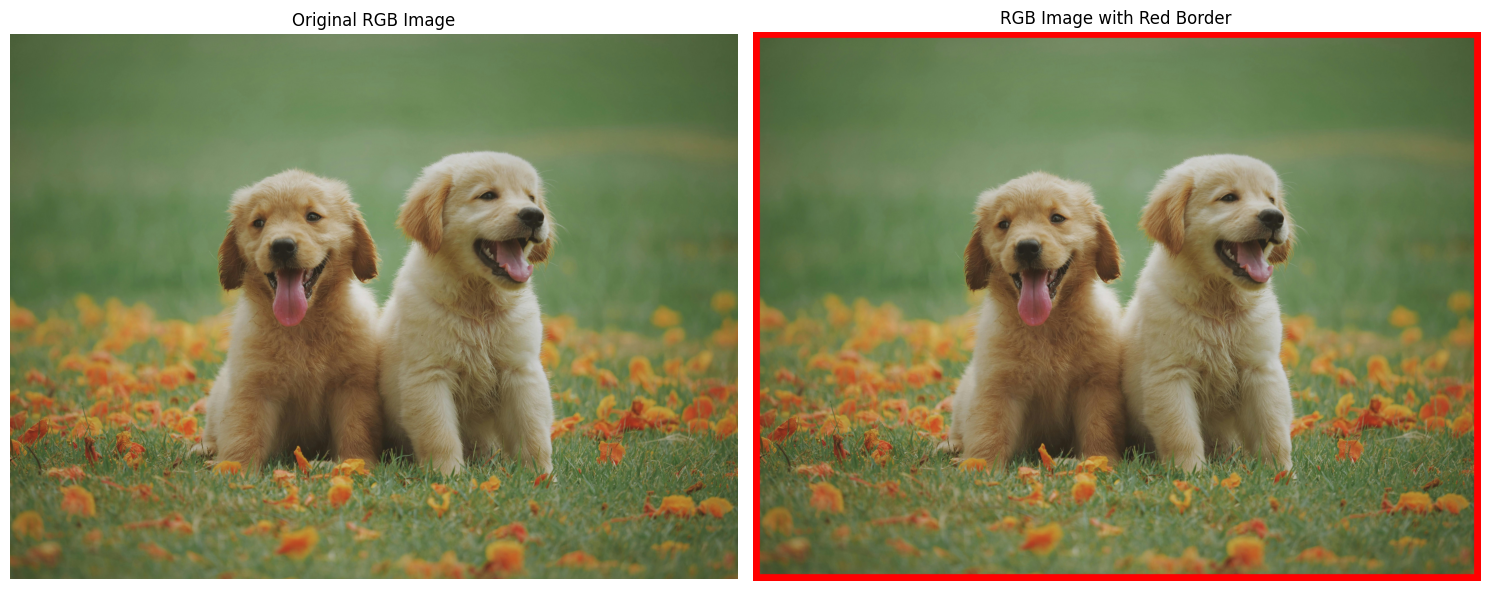

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

original_image = cv2.imread('/content/pexels-chevanon-1108099.jpg')

if original_image is None:
    print("Error: Image not found or could not be loaded.")
else:
    # Convert BGR to RGB for displaying with matplotlib
    original_image_rgb = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)

    # Define border parameters
    top_border = 50
    bottom_border = 50
    left_border = 50
    right_border = 50
    border_color = [255, 0, 0] # Red color in RGB
    border_type = cv2.BORDER_CONSTANT # Use a constant color border

    bordered_image_bgr = cv2.copyMakeBorder(
        original_image,
        top_border,
        bottom_border,
        left_border,
        right_border,
        border_type,
        value=border_color[::-1] # OpenCV expects BGR, so reverse the RGB color
    )
    bordered_image_rgb = cv2.cvtColor(bordered_image_bgr, cv2.COLOR_BGR2RGB)

    # Display the original and bordered images
    plt.figure(figsize=(15, 8))

    plt.subplot(1, 2, 1)
    plt.imshow(original_image_rgb)
    plt.title('Original RGB Image')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(bordered_image_rgb)
    plt.title('RGB Image with Red Border')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

### Pixel Complement Transformation

The pixel complement transformation, often referred to as image negation, is a simple but effective image processing technique. It inverts the intensity of each pixel in an image. For an 8-bit grayscale image where pixel values range from 0 (black) to 255 (white), the transformation is defined as:

$p_{out} = 255 - p_{in}$

Where $p_{in}$ is the input pixel value and $p_{out}$ is the output pixel value. This transformation results in an image where dark areas become light and light areas become dark, similar to a photographic negative. It can be useful for enhancing white or gray detail embedded in dark regions of an image.

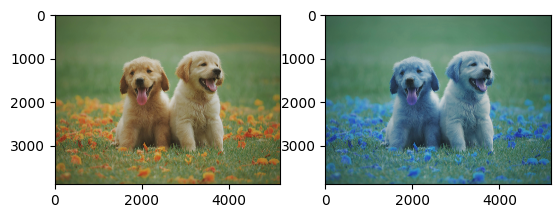

In [ ]:
img = cv2.imread("/content/pexels-chevanon-1108099.jpg")
img2=img.copy()
plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img,cv2.COLOR_BGR2RGB))
h, w, c = img.shape
for i in range(h):
    for j in range(w):
        img2[i][j] = img2[i][j]-255

plt.subplot(1,2,2)
plt.imshow(img2)
plt.show()